unlimited_non_competitive_R_unlimited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

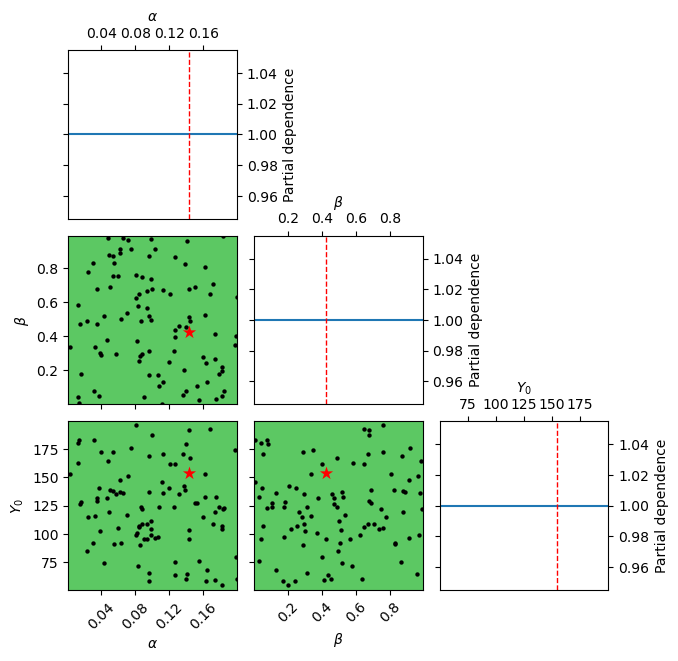

unlimited_non_competitive_R_limited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

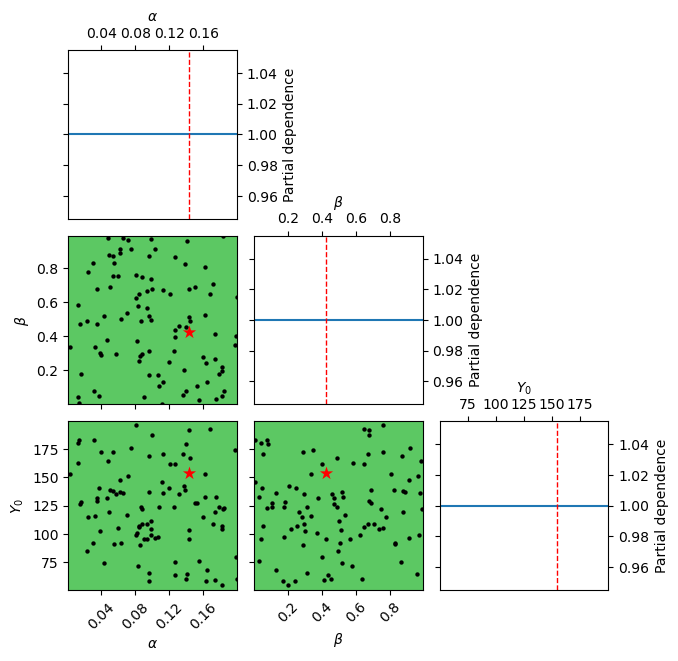

unlimited_non_competitive_R_limited_competitive_Y


<Figure size 1500x350 with 0 Axes>

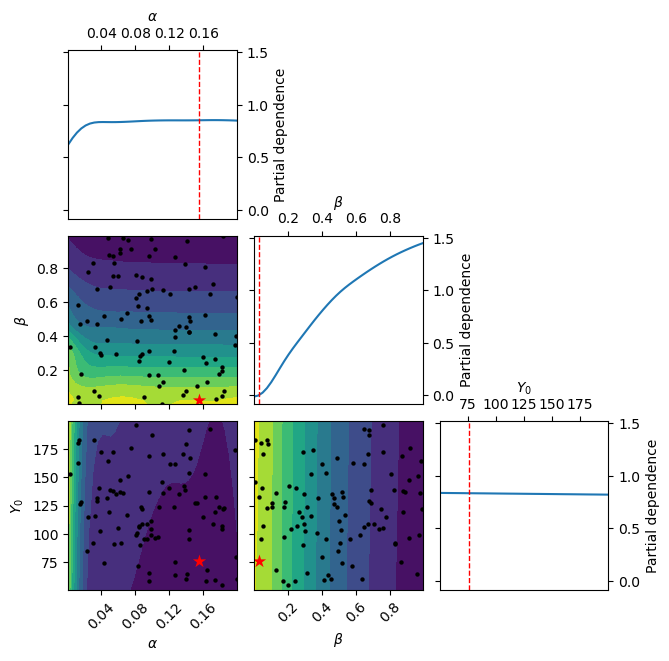

limited_non_competitive_R_unlimited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

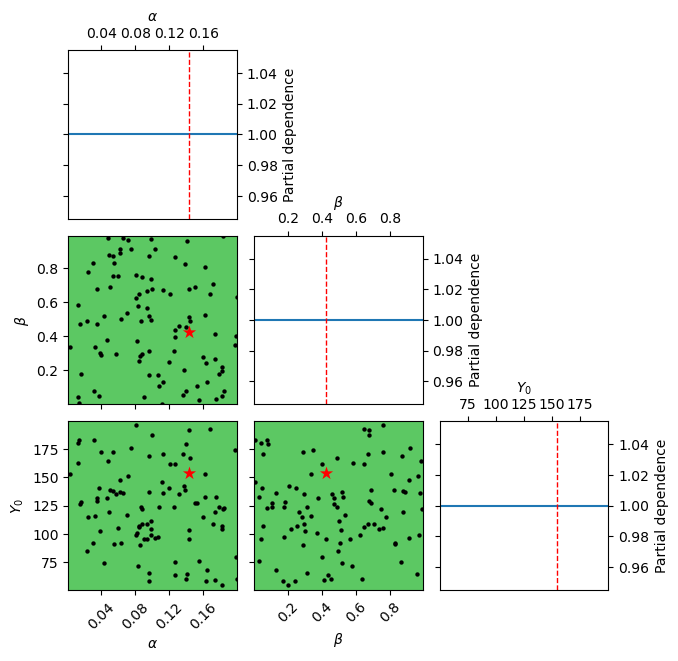

limited_non_competitive_R_limited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

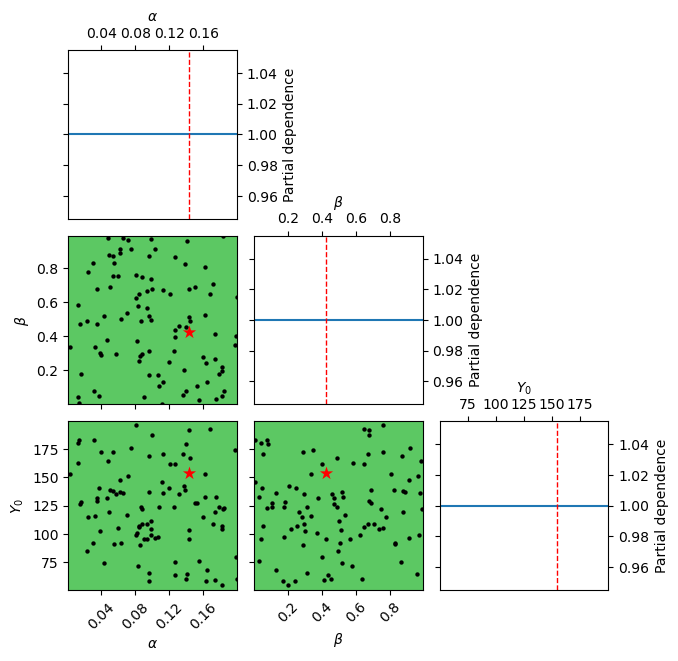

limited_non_competitive R_limited_competitive_Y


<Figure size 1500x350 with 0 Axes>

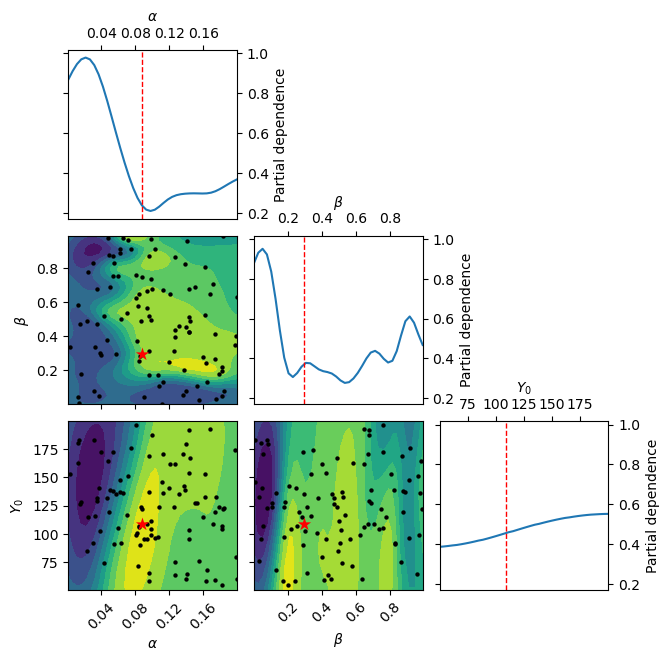

limited_competitive_R_unlimited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

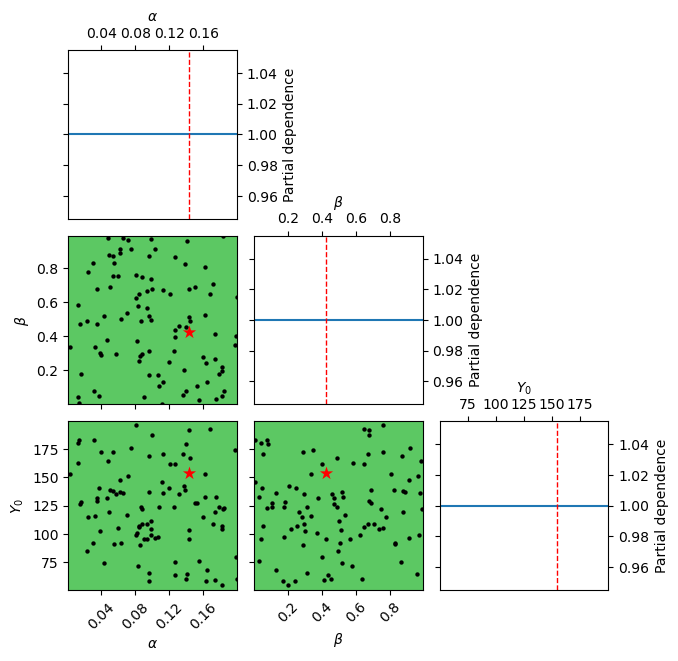

limited_competitive_R_limited_non_competitive_Y


<Figure size 1500x350 with 0 Axes>

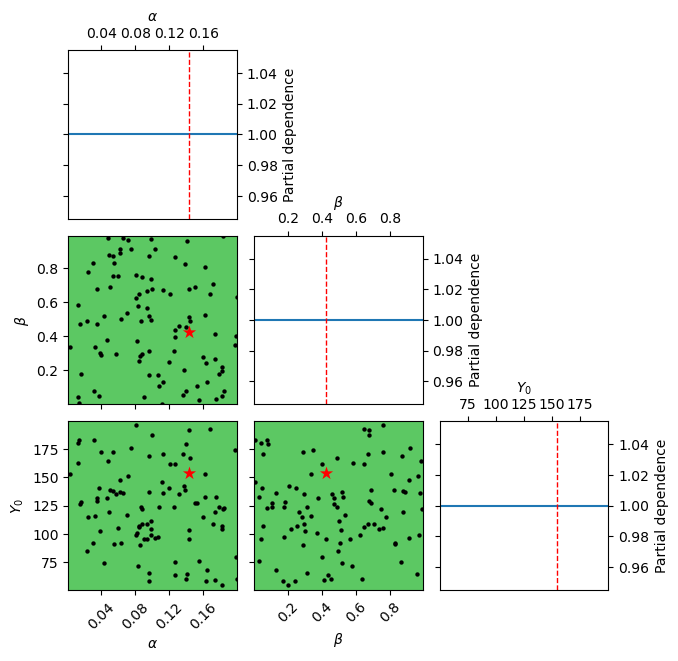

limited_competitive_R_limited_competitive_Y


<Figure size 1500x350 with 0 Axes>

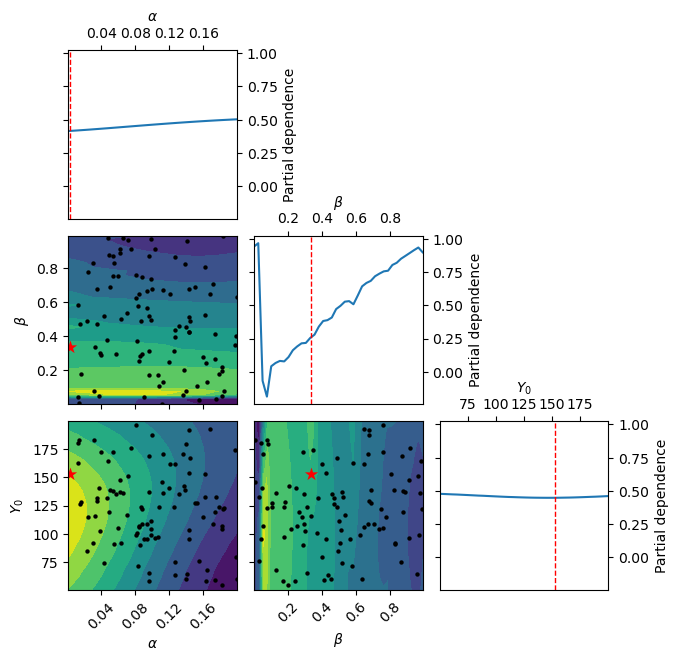

In [1]:
import matplotlib.pyplot as plt
from skopt import gp_minimize, dump, load
from skopt.plots import plot_convergence, plot_evaluations, plot_objective
from skopt.space import Integer, Real
from model_variations import *
from parameters import *


model_list = [ulR_ulY, ulR_lY, ulR_cY, lR_ulY, lR_lY, lR_cY, cR_ulY, cR_lY, cR_cY]


#target: slope negative for R1 and R2. These are the only points we "know" experimentally

target = -0.1 #small but the important thing is, that it is negative

def slope_calc(α_h, β_h, Y0 , model): 
    
    R1, R2 = [50,100]

 
    #prepare parameter dictionary
    parameters = dict()
    
    parameters['α'] = α_h
    parameters['β'] = β_h/l_samples
    
    parameters['γ'] = γ
    parameters['l'] = l_samples
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    parameters['Y_max'] = Y0
    parameters['N'] = N


    x0 = np.ones([N])*x_init
    init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 
    
    parameters['R'] = R1
    y1 = simulation_wrapper(init_state,parameters,model,R_fernandes, sim_time, dt, [True, sampling])[-1, 2,:]
    

    parameters['R'] = R2
    y2 = simulation_wrapper(init_state,parameters,model,R_fernandes, sim_time, dt, [True, sampling])[-1, 2,:]
    
    slope_here = (np.mean(y1[long_ind] - y2[long_ind])/ np.mean(y1[short_ind] - y2[short_ind]))
    
    if slope_here > 0: 
        #this ensured that if we cant get the slope negative the dependencies are flat!
        #because we are only interested in whether we can gain a competition in the 2nd part, not if we can
        #and the actual RMSE is agnostic to whether it is approached from left or right
        #this way we ensure that we need to approach it from the left (or rather within the negative realm)
        #it also means that there is a parameter setting where the slope are less strong that requested we will see a
        #non-flat dependency
        return 1
    else:    
        return (target - slope_here)**2
    
    
calls = 100
starts = 100
params_to_opt = [['$\\alpha$', 0.001, 0.2],
                 ['$\\beta$', 0.001, 0.99],
                 ['$Y_0$', N/2, N*2]
                ]

opt_type = 'float'
dimensions = []

for rang in params_to_opt:
    if type(rang[2]) is int:
        dimensions.append(Integer(low=rang[1], high=rang[2], name=rang[0]))
    else:
        dimensions.append(Real(low=rang[1], high=rang[2], name=rang[0]))

parameter_names = []
for rang in params_to_opt:
    parameter_names.append(rang[0])
    
def run_opt(model_h, fig_name): 
        
    def opti_metrics(params):
        return slope_calc(params[0], params[1], params[2], model_h )

    both_results = gp_minimize(opti_metrics,     # wrapper for network which returns the RMSE as performance measurement 
                          dimensions,              # parameter bounds
                          acq_func="EI",           # the acquisition function
                          n_calls=calls,           # the number of evaluations of f 
                          n_random_starts=starts,  # the number of random initialization points
                          noise=1e-10,             # the noise level (optional)
                          random_state=123)


    plt.figure(figsize=(15,3.5))
    plot_objective(both_results, dimensions=parameter_names)
    #plt.savefig(figures_path+fig_name+'optimization.pdf')
    plt.show()

for m in range(len(model_list)): 
    print(model_descriptions[m])
    run_opt(model_list[m], model_descriptions[m])